# 03e - Visualizations
Plotting only, no training or GPU. Reads saved CSV/JSON files from `03d`.

Requires `03d` to have saved `final_per_class_table.csv` and `final_per_city_table.csv`:

```python
per_class_rows = []
for arch in BEST_RUN_NAME:
    for split_name in TEST_SPLITS:
        m = final_test_results[arch][split_name]['metrics']
        for cls_idx, cls_name in enumerate(CLASS_NAMES):
            per_class_rows.append({
                'architecture': arch, 'split': split_name, 'class': cls_name,
                'IoU': m['per_class_IoU'][cls_idx], 'F1': m['per_class_F1'][cls_idx],
            })
per_class_full_df = pd.DataFrame(per_class_rows)
per_class_full_df.to_csv(f'{CKPT_DIR}/final_per_class_table.csv', index=False)
per_city_df.to_csv(f'{CKPT_DIR}/final_per_city_table.csv', index=False)
print('Saved final_per_class_table.csv and final_per_city_table.csv to', CKPT_DIR)
```

**Cell 1:** Mount Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json as json_module
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DRIVE_FOLDER = '/content/drive/MyDrive/lulc_dataset'
CKPT_DIR = f'{DRIVE_FOLDER}/All Model Weights'

CLASS_NAMES = [
    "Tree cover", "Shrubland", "Grassland", "Cropland", "Built-up",
    "Bare/sparse vegetation", "Permanent water", "Herbaceous wetland", "Mangroves",
]

print('Checkpoint folder:', CKPT_DIR)
print('Files available:', sorted(os.listdir(CKPT_DIR))[:10], '...')


Mounted at /content/drive
Checkpoint folder: /content/drive/MyDrive/lulc_dataset/All Model Weights
Files available: ['deeplabv3plus_ssl4eo_moco_best.pt', 'deeplabv3plus_ssl4eo_moco_log.json', 'fcdensenet_best.pt', 'fcdensenet_log.json', 'final_comparison_table.csv', 'final_per_city_table.csv', 'final_per_class_table.csv', 'fpn_ssl4eo_moco_best.pt', 'fpn_ssl4eo_moco_log.json', 'manet_ssl4eo_moco_best.pt'] ...


**Cell 2:** Load the comparison table.

In [2]:
comparison_df = pd.read_csv(f'{CKPT_DIR}/final_comparison_table.csv')
comparison_df


,architecture,best_run,test_same_region_mIoU,test_same_region_OA,test_same_region_macro_F1,test_similar_unseen_mIoU,test_similar_unseen_OA,test_similar_unseen_macro_F1,test_dissimilar_mIoU,test_dissimilar_OA,test_dissimilar_macro_F1
0,UnetPlusPlus,unetplusplus_ssl4eo_moco,0.453495,0.741890,0.557083,0.322619,0.697869,0.403956,0.226860,0.710436,0.280591
1,FPN,fpn_ssl4eo_moco,0.450487,0.732348,0.557661,0.330548,0.716871,0.409945,0.214168,0.683346,0.262751
2,PSPNet,pspnet_ssl4eo_moco,0.445427,0.713280,0.564771,0.330211,0.703453,0.417047,0.231672,0.688839,0.293806
3,FCDenseNet,fcdensenet,0.437414,0.716711,0.554487,0.327576,0.711394,0.414787,0.227832,0.711089,0.283452
4,DeepLabV3Plus,deeplabv3plus_ssl4eo_moco,0.430182,0.714616,0.539844,0.330276,0.713865,0.410202,0.214041,0.703784,0.258648
5,SegNet,segnet,0.406325,0.699451,0.514535,0.313290,0.683108,0.393239,0.222572,0.657252,0.279239
6,MAnet,manet_ssl4eo_moco,0.390268,0.706532,0.497279,0.346152,0.726589,0.431335,0.231068,0.720625,0.288929
7,Unet,unet_ssl4eo_moco_finetune,0.372363,0.717301,0.464484,0.332638,0.722152,0.407948,0.221680,0.729750,0.269220


**Cell 3:** Rebuild training histories from saved logs.

In [3]:
def load_history(run_name):
    log_path = f'{CKPT_DIR}/{run_name}_log.json'
    with open(log_path) as f:
        return json_module.load(f)

PILOT_CONFIGS = [
    'unet_ssl4eo_moco_finetune', 'unet_ssl4eo_moco_frozen', 'unet_softcon_finetune',
    'unet_imagenet_finetune', 'unet_random_init',
]
pilot_histories = {name: {'history': load_history(name)} for name in PILOT_CONFIGS}

all_histories = {}
for _, row in comparison_df.iterrows():
    all_histories[row['architecture']] = {'history': load_history(row['best_run'])}

print('Loaded pilot histories:', list(pilot_histories.keys()))
print('Loaded final architecture histories:', list(all_histories.keys()))


Loaded pilot histories: ['unet_ssl4eo_moco_finetune', 'unet_ssl4eo_moco_frozen', 'unet_softcon_finetune', 'unet_imagenet_finetune', 'unet_random_init']
Loaded final architecture histories: ['UnetPlusPlus', 'FPN', 'PSPNet', 'FCDenseNet', 'DeepLabV3Plus', 'SegNet', 'MAnet', 'Unet']


**Training curves:** training loss and validation mIoU per epoch.

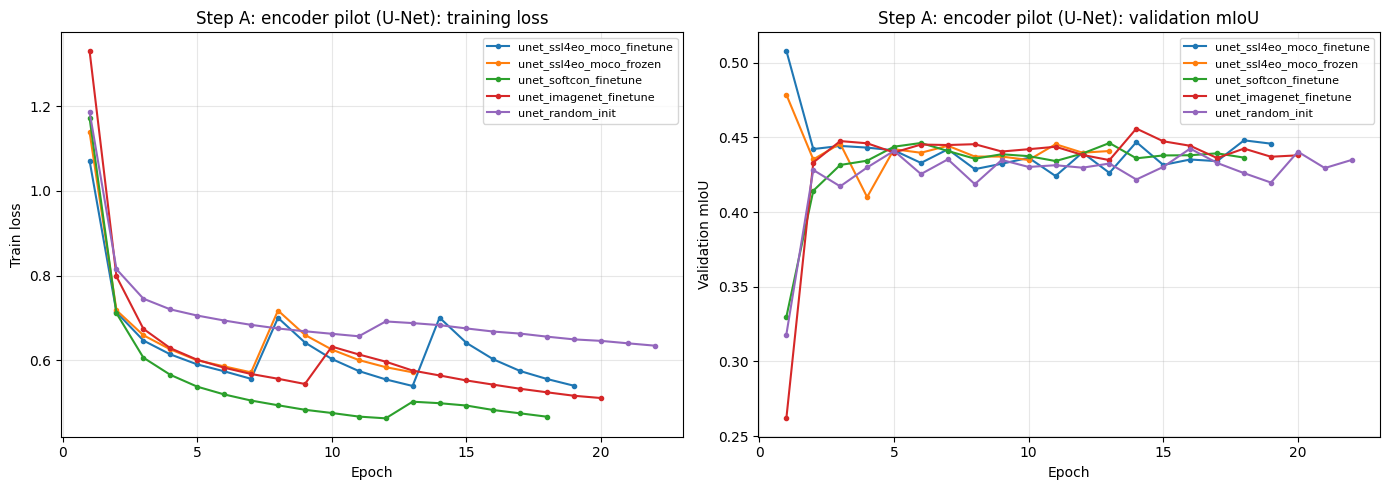

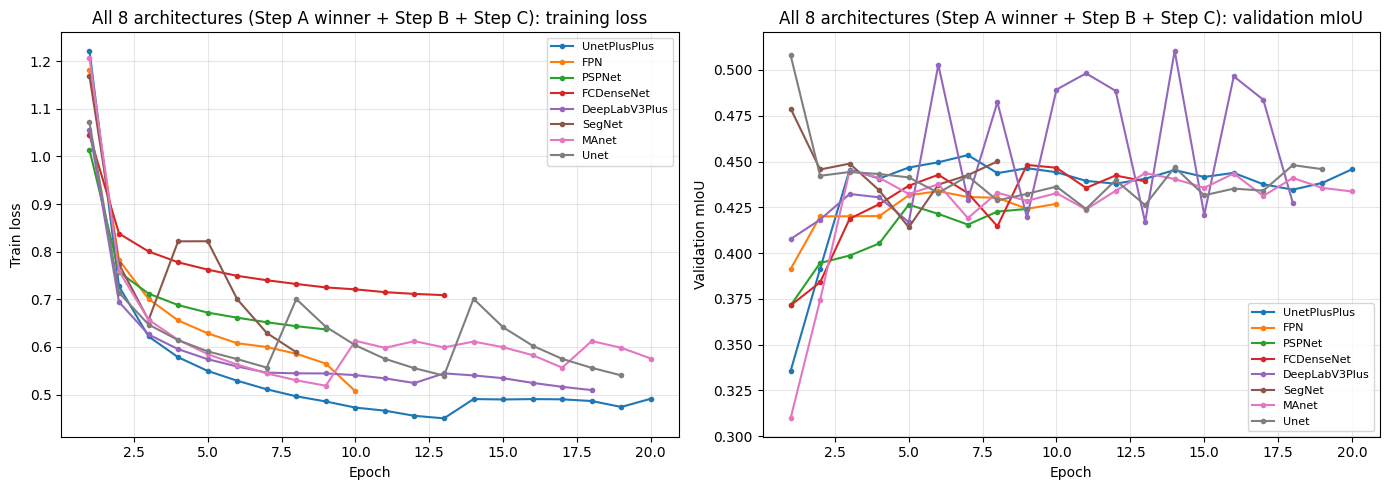

In [4]:
def plot_training_curves(results_dict, title, keys=None):
    keys = keys or list(results_dict.keys())
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name in keys:
        history = results_dict[name]['history']
        if not history:
            continue
        epochs = [h['epoch'] for h in history]
        axes[0].plot(epochs, [h['train_loss'] for h in history], marker='o', markersize=3, label=name)
        axes[1].plot(epochs, [h['val_mIoU'] for h in history], marker='o', markersize=3, label=name)

    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Train loss')
    axes[0].set_title(f'{title}: training loss'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Validation mIoU')
    axes[1].set_title(f'{title}: validation mIoU'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_curves(pilot_histories, 'Step A: encoder pilot (U-Net)')
plot_training_curves(all_histories, 'All 8 architectures (Step A winner + Step B + Step C)')


**Test-set comparison chart:** mIoU per architecture, by test split.

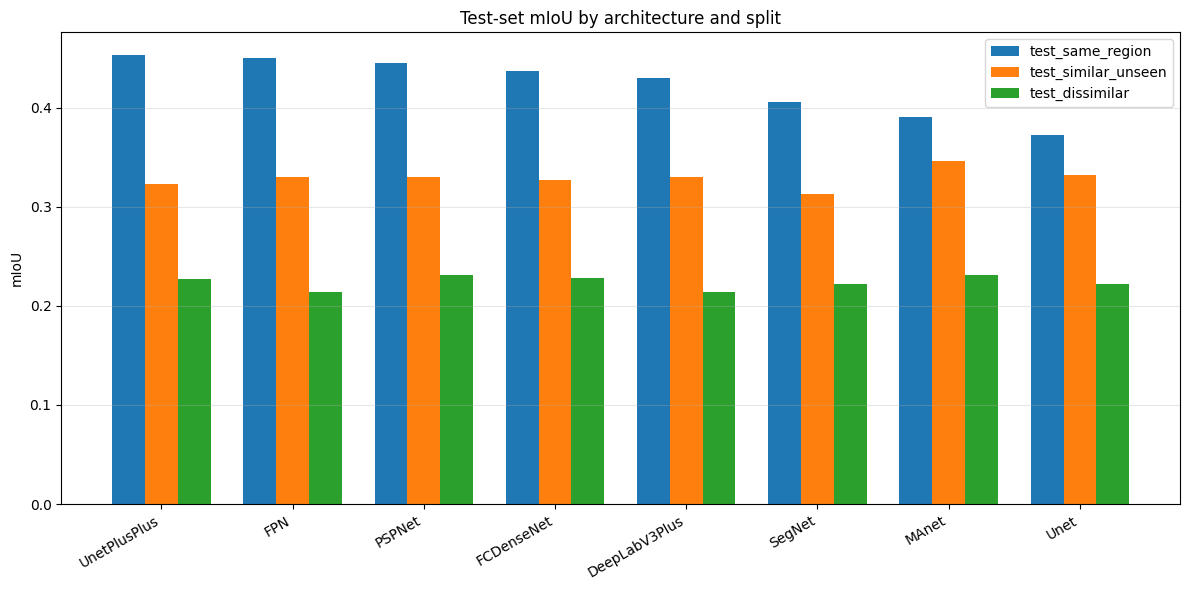

In [5]:
splits = ['test_same_region', 'test_similar_unseen', 'test_dissimilar']
archs = comparison_df['architecture'].tolist()
x = np.arange(len(archs))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, split in enumerate(splits):
    values = comparison_df[f'{split}_mIoU'].values
    ax.bar(x + (i - 1) * width, values, width, label=split)

ax.set_xticks(x)
ax.set_xticklabels(archs, rotation=30, ha='right')
ax.set_ylabel('mIoU')
ax.set_title('Test-set mIoU by architecture and split')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Per-class breakdown chart:** winning architecture, same-region test.

Best architecture on test_same_region: UnetPlusPlus


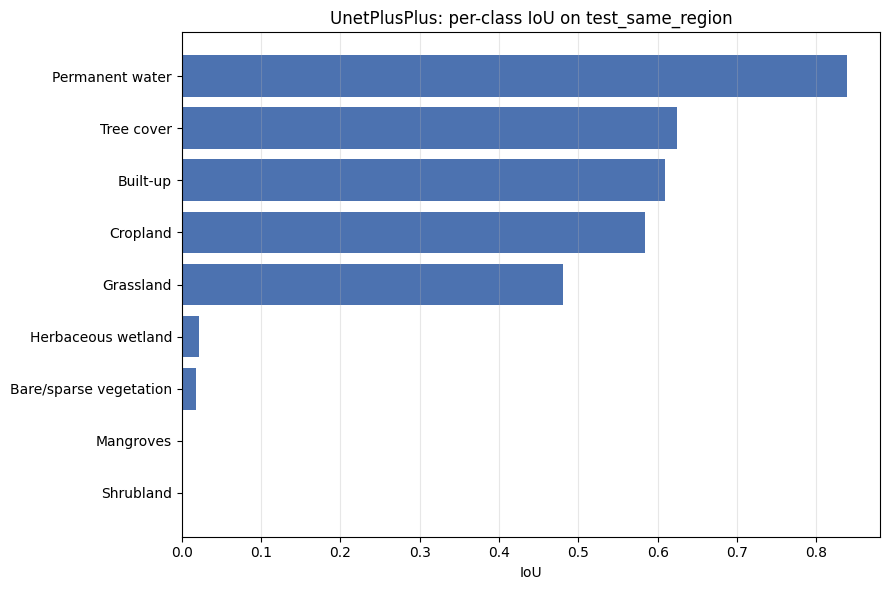

In [6]:
per_class_full_df = pd.read_csv(f'{CKPT_DIR}/final_per_class_table.csv')

best_arch = comparison_df.iloc[0]['architecture']
print('Best architecture on test_same_region:', best_arch)

subset = per_class_full_df[(per_class_full_df['architecture'] == best_arch) &
                           (per_class_full_df['split'] == 'test_same_region')]
subset = subset.sort_values('IoU', ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(subset['class'], subset['IoU'], color='#4C72B0')
ax.set_xlabel('IoU')
ax.set_title(f'{best_arch}: per-class IoU on test_same_region')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


**Per-class heatmap:** all 8 architectures, same-region test.

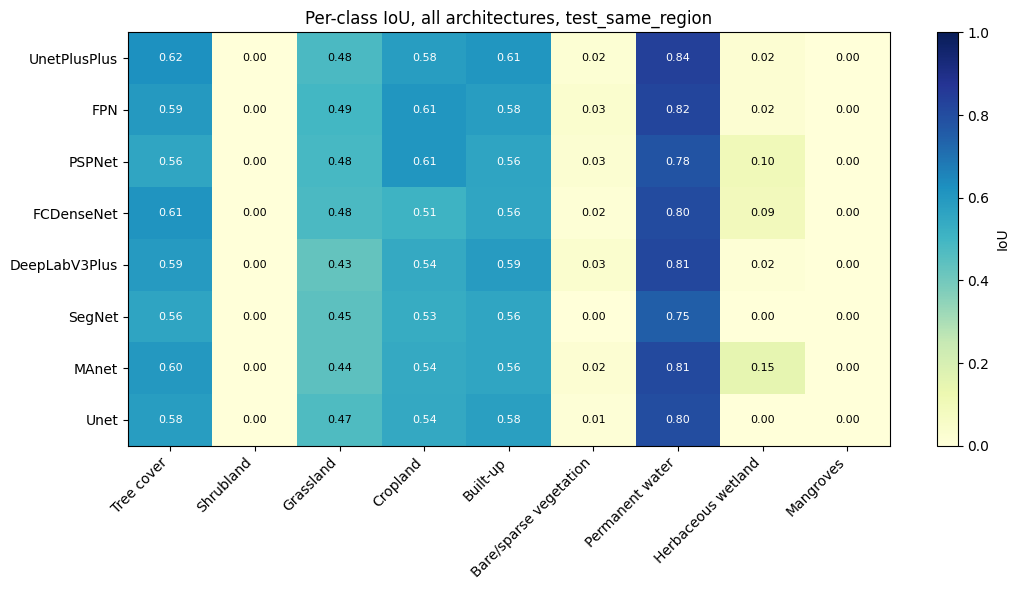

In [7]:
pivot = per_class_full_df[per_class_full_df['split'] == 'test_same_region'].pivot(
    index='architecture', columns='class', values='IoU'
).reindex(index=comparison_df['architecture'], columns=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(pivot.values, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                color='white' if val > 0.5 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='IoU')
ax.set_title('Per-class IoU, all architectures, test_same_region')
plt.tight_layout()
plt.show()


**Per-city breakdown chart:** winning architecture, same-region test, by city.

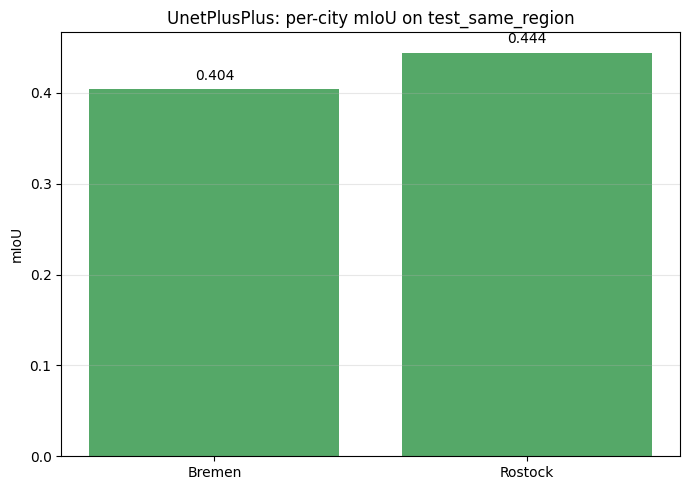

In [8]:
per_city_df = pd.read_csv(f'{CKPT_DIR}/final_per_city_table.csv')

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(per_city_df['city'], per_city_df['mIoU'], color='#55A868')
for i, row in per_city_df.iterrows():
    ax.text(i, row['mIoU'] + 0.01, f"{row['mIoU']:.3f}", ha='center')
ax.set_ylabel('mIoU')
ax.set_title(f'{best_arch}: per-city mIoU on test_same_region')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Done.** All plots ready for the report.